In [4]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

Found 8 csv files in C:\Users\Timothy Louis\Desktop\FYP\Proj_Folds\data\FYP_D137_Zhang2025_data\Zhang2025_digitised


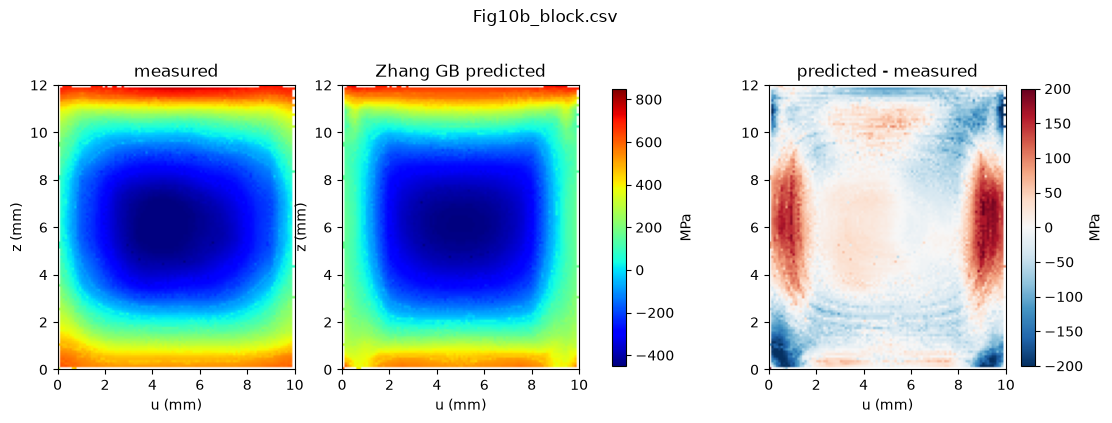

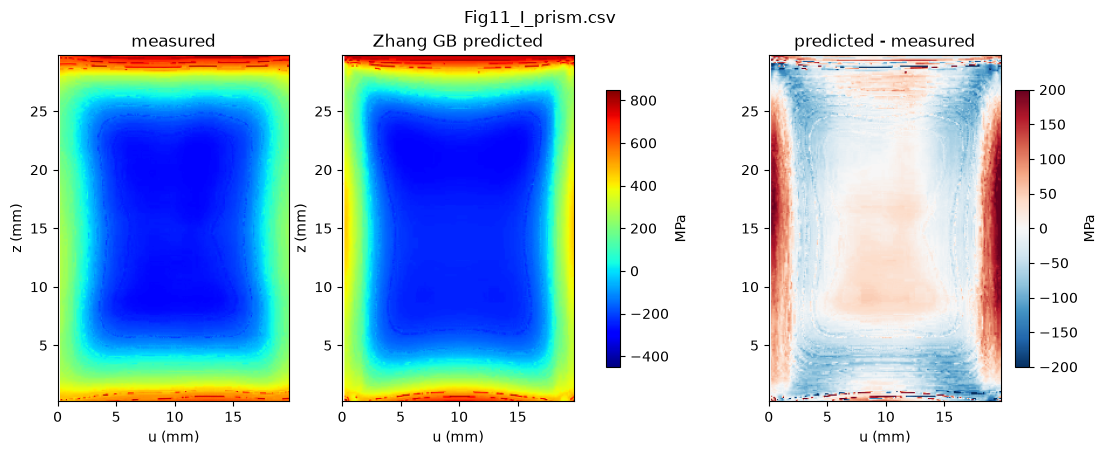

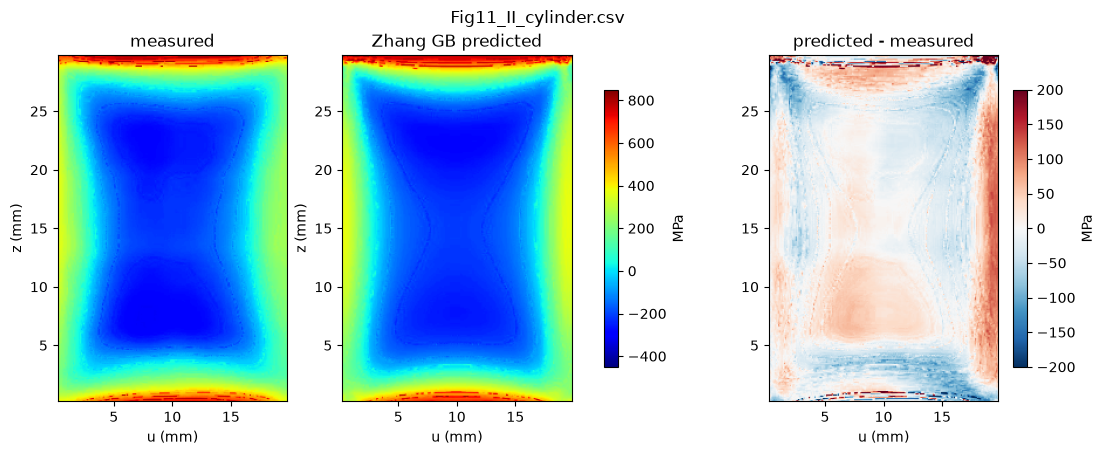

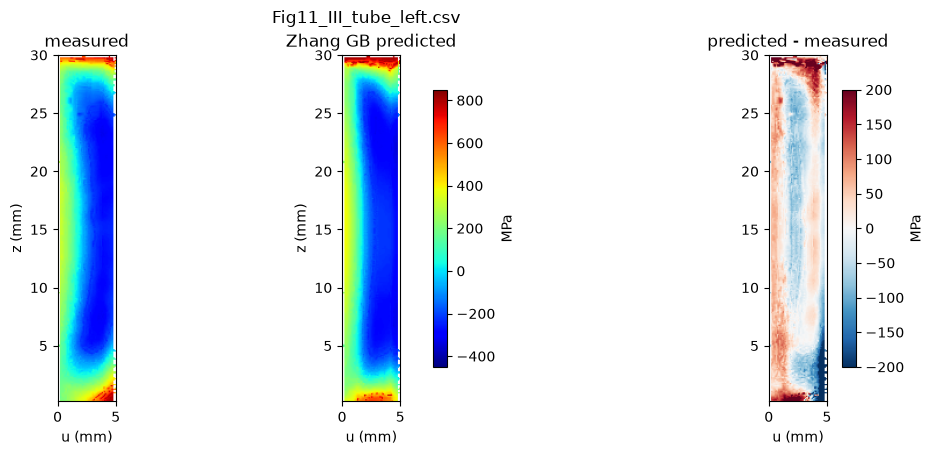

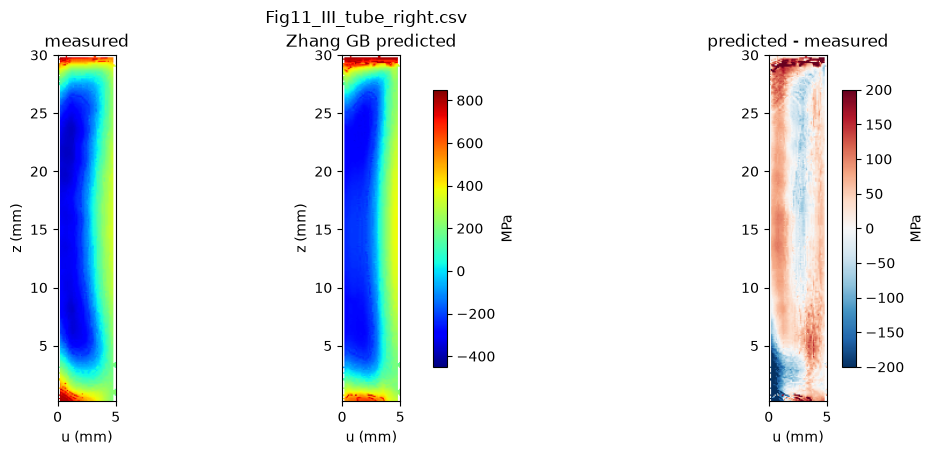

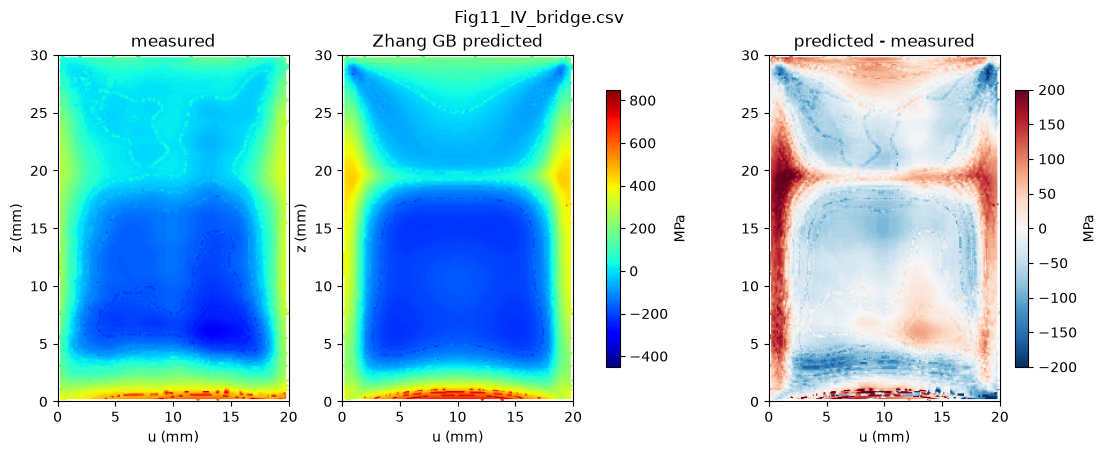

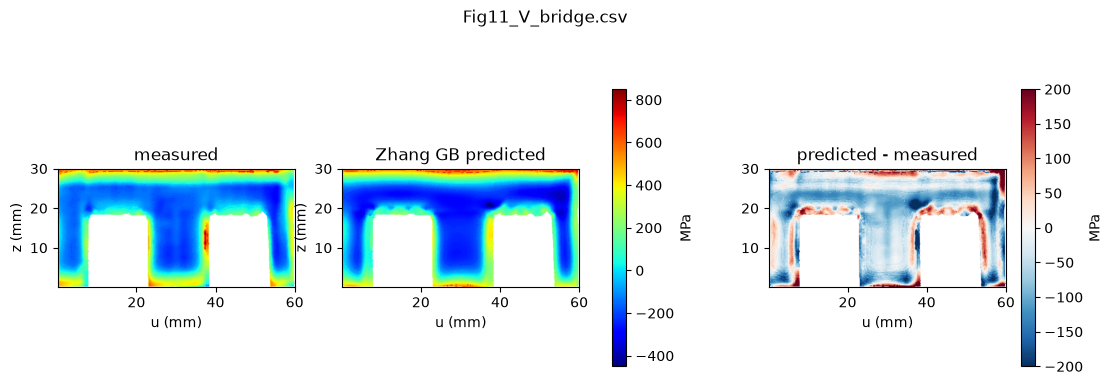

,file,N,RMSE_MPa,bias_MPa,pct_within_100,meas_min,meas_max,note
0,Fig10b_block.csv,11608,60.4,0.3,89.0,-471.0,756.0,
1,Fig11_I_prism.csv,58018,59.7,-0.8,91.0,-295.0,797.0,
2,Fig11_II_cylinder.csv,58016,48.8,0.7,95.0,-309.0,800.0,
3,Fig11_III_tube_left.csv,13705,80.7,1.5,89.0,-321.0,796.0,
4,Fig11_III_tube_right.csv,13688,72.6,22.4,91.0,-373.0,796.0,
5,Fig11_IV_bridge.csv,58163,64.6,-5.9,90.0,-288.0,798.0,
6,Fig11_V_bridge.csv,122024,93.5,-39.1,75.0,-302.0,800.0,
7,Fig12a_bridge_top_profile.csv,951,NaN,NaN,NaN,NaN,NaN,peak-to-valley = 0.92 mm (paper: 0.94)


In [ ]:
folder = Path("Zhang2025_digitised")

files = sorted(folder.glob("*.csv"))
print(f"Found {len(files)} csv files in {folder.resolve()}")   # should say 8

rows = []
for f in files:
    d = pd.read_csv(f)

    # bridge-profile file has different columns: only report peak-to-valley
    if "deformation_mm" in d.columns:
        rows.append(dict(file=f.name, N=len(d), RMSE_MPa=np.nan, bias_MPa=np.nan,
                         pct_within_100=np.nan, meas_min=np.nan, meas_max=np.nan,
                         note=f"peak-to-valley = {d.deformation_mm.max()-d.deformation_mm.min():.2f} mm (paper: 0.94)"))
        continue

    # the check: RMSE between predicted and measured
    e = d.zhang_GB_predicted_MPa - d.measured_MPa
    rows.append(dict(file=f.name, N=len(d),
                     RMSE_MPa=round(float(np.sqrt((e**2).mean())), 1),
                     bias_MPa=round(float(e.mean()), 1),
                     pct_within_100=round(float(100*(e.abs() < 100).mean())),
                     meas_min=round(float(d.measured_MPa.min())),
                     meas_max=round(float(d.measured_MPa.max())), note=""))

    # rebuild the map on the 0.1 mm grid
    s = 0.1
    iu = np.round((d.u_mm - d.u_mm.min())/s).astype(int)
    iz = np.round((d.z_mm - d.z_mm.min())/s).astype(int)
    M = np.full((iz.max()+1, iu.max()+1), np.nan); P = M.copy()
    M[iz, iu] = d.measured_MPa
    P[iz, iu] = d.zhang_GB_predicted_MPa
    ext = [d.u_mm.min()-s/2, d.u_mm.max()+s/2, d.z_mm.min()-s/2, d.z_mm.max()+s/2]

    # plot: measured, predicted, difference
    fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
    for a, A, t in zip(ax[:2], [M, P], ["measured", "Zhang GB predicted"]):
        im = a.imshow(A, origin="lower", extent=ext, cmap="jet", vmin=-450, vmax=850)
        a.set(title=t, xlabel="u (mm)", ylabel="z (mm)")
    fig.colorbar(im, ax=ax[:2], shrink=.8, label="MPa")
    im = ax[2].imshow(P - M, origin="lower", extent=ext, cmap="RdBu_r", vmin=-200, vmax=200)
    ax[2].set(title="predicted - measured", xlabel="u (mm)")
    fig.colorbar(im, ax=ax[2], shrink=.8, label="MPa")
    fig.suptitle(f.name)
    plt.show()

results = pd.DataFrame(rows)
results